# Real-world example

We will now use a more real-world model. For this, we make use of the time
series data from the Jena climate dataset:

```
Max Planck Institute for Biogeochemistry. Jena Climate Dataset (Weather Station Data, 2009–2016). Jena, Germany. https://www.bgc-jena.mpg.de/wetter/ (accessed 2026-10-20). Licensed under CC BY 4.0.
```

Specifically, we will make a neural network that predicts the expected relative
humidity for a given week of the year.

## Training a model

First, we fetch the dataset.

In [41]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import altair as alt
import torch
from util.nn import ReLUFNN, train, load_pytorch_model_into_db

In [42]:
DATASET_PATH = Path("datasets/jena_climate_2009_2016.csv")
MODEL_PATH = Path("models/jena_rh_weekly.pt")
FORCE_RETRAIN = False
PLOT_PATH = Path("jena_weekly.png")


In [43]:
if not DATASET_PATH.exists():
    raise Exception("Dataset is not available, run ./datasets/fetch.sh to retrieve it.")

df = pd.read_csv(DATASET_PATH)
df

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.30,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.40,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.90,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.20,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.10,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
420446,31.12.2016 23:20:00,1000.07,-4.05,269.10,-8.13,73.10,4.52,3.30,1.22,2.06,3.30,1292.98,0.67,1.52,240.0
420447,31.12.2016 23:30:00,999.93,-3.35,269.81,-8.06,69.71,4.77,3.32,1.44,2.07,3.32,1289.44,1.14,1.92,234.3
420448,31.12.2016 23:40:00,999.82,-3.16,270.01,-8.21,67.91,4.84,3.28,1.55,2.05,3.28,1288.39,1.08,2.00,215.2
420449,31.12.2016 23:50:00,999.81,-4.23,268.94,-8.53,71.80,4.46,3.20,1.26,1.99,3.20,1293.56,1.49,2.16,225.8


We are only interested in the relative humidity, so let's drop everything else
and parse the datetime while we're at it.

In [44]:
rh_colname = "rh (%)"

df = df[["Date Time", rh_colname]]

df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df["year"] = df["Date Time"].dt.year
df["day_of_year"] = df["Date Time"].dt.dayofyear
df["week"] = (df["day_of_year"] - 1) // 7

df


,Date Time,rh (%),year,day_of_year,week
0,2009-01-01 00:10:00,93.30,2009,1,0
1,2009-01-01 00:20:00,93.40,2009,1,0
2,2009-01-01 00:30:00,93.90,2009,1,0
3,2009-01-01 00:40:00,94.20,2009,1,0
4,2009-01-01 00:50:00,94.10,2009,1,0
...,...,...,...,...,...
420446,2016-12-31 23:20:00,73.10,2016,366,52
420447,2016-12-31 23:30:00,69.71,2016,366,52
420448,2016-12-31 23:40:00,67.91,2016,366,52
420449,2016-12-31 23:50:00,71.80,2016,366,52


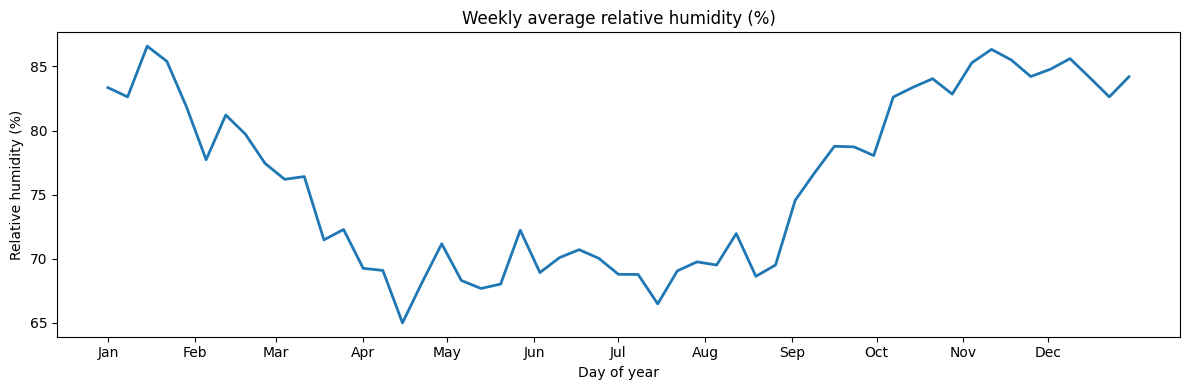

In [45]:
weekly = df.groupby(["year", "week"])[rh_colname].mean().reset_index()
weekly_mean = weekly.groupby("week")[rh_colname].mean()
week_day = weekly_mean.index * 7 + 1

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week_day, weekly_mean.values, linewidth=2, label="Average")

ax.set_title("Weekly average relative humidity (%)")
ax.set_xlabel("Day of year")
ax.set_ylabel("Relative humidity (%)")
month_starts = pd.to_datetime("2000-" + pd.Index([f"{m:02d}-01" for m in range(1, 13)]))
ax.set_xticks(month_starts.dayofyear)
ax.set_xticklabels(month_starts.strftime("%b"))

plt.tight_layout()
plt.show()


We will train a neural network on the weekly average of the sensor values,
using all years as the training data.

In [ ]:
x = (weekly["week"] * 7 + 1).to_numpy()
y = weekly[rh_colname].to_numpy()

torch.manual_seed(0)

model = ReLUFNN(input_size=1, hidden_size=50, num_hidden_layers=1, output_size=1)

if MODEL_PATH.exists() and not FORCE_RETRAIN:
    print(f"Reusing saved model {MODEL_PATH}")
    model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
else:
    if MODEL_PATH.exists():
        print("Deleting existing trained model because FORCE_RETRAIN is set")
        MODEL_PATH.unlink()

    x_mean, x_std = x.mean(), x.std()
    y_mean, y_std = y.mean(), y.std()

    train(
        model,
        (x - x_mean) / x_std,
        (y - y_mean) / y_std,
        epochs=10_000,
    )

    # Fold the normalisation into the first/last layers so the saved model
    # still maps raw day-of-year to raw humidity.
    with torch.no_grad():
        first = model.linear_relu_stack[0]
        first.weight.div_(x_std)
        first.bias.sub_(first.weight.squeeze(1) * x_mean)

        last = model.linear_relu_stack[-1]
        last.weight.mul_(y_std)
        last.bias.mul_(y_std).add_(y_mean)

    torch.save(model.state_dict(), MODEL_PATH)

model.eval()
with torch.no_grad():
    grid = torch.linspace(1, 365, 365).unsqueeze(1)
    prediction = model(grid).squeeze(1).numpy()

week_day = weekly_mean.index * 7 + 1

month_starts = pd.to_datetime("2000-" + pd.Index([f"{m:02d}-01" for m in range(1, 13)]))

# We swap to altair. More work, but consistent with the other graphs in the
# paper.
observed = pd.DataFrame({
    "day_of_year": week_day,
    "humidity": weekly_mean.values,
    "series": "Observed weekly average",
})
predicted = pd.DataFrame({
    "day_of_year": grid.squeeze(1).numpy(),
    "humidity": prediction,
    "series": "Neural network prediction",
})
plot_data = pd.concat([observed, predicted], ignore_index=True)

PRINT_PALETTE = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
    "#56B4E9",
    "#F0E442",
    "#000000",
]

series_domain = ["Observed weekly average", "Neural network prediction"]
month_days = month_starts.dayofyear.tolist()
month_label_expr = " : ".join(
    f"datum.value == {day} ? '{label}'"
    for day, label in zip(month_days, month_starts.strftime("%b"))
) + " : ''"

chart = (
    alt.Chart(plot_data.sort_values("day_of_year"))
    .mark_line(strokeWidth=2)
    .encode(
        x=alt.X(
            "day_of_year:Q",
            title="Week of year",
            axis=alt.Axis(values=month_days, labelExpr=month_label_expr),
        ),
        y=alt.Y("humidity:Q", title="Relative humidity (%)", scale=alt.Scale(domain=(60, 90))),
        color=alt.Color(
            "series:N",
            title=None,
            scale=alt.Scale(domain=series_domain, range=PRINT_PALETTE[:2]),
            legend=alt.Legend(orient="bottom-right"),
        ),
        strokeDash=alt.StrokeDash(
            "series:N",
            legend=None,
            scale=alt.Scale(domain=series_domain, range=[[6, 3], [1, 0]]),
        ),
    )
    .properties(
        width=600,
        height=260,
        title=alt.TitleParams(
            text="Expected relative humidity (%) per week (2009-2016)",
            fontSize=14,
        ),
    )
    .configure(
        font="serif",
        axis=alt.AxisConfig(labelFontSize=13, titleFontSize=14, grid=False),
        legend=alt.LegendConfig(labelFontSize=13, titleFontSize=14),
        view=alt.ViewConfig(strokeOpacity=0),
    )
)

chart.save(PLOT_PATH, scale_factor=2)
chart


Reusing saved model models/jena_rh_weekly.pt


alt.Chart(...)

## Verifying the model

Now we can start some verification tasks to see if our model behaves as
expected. Since we are dealing with relative humidity, a percentage value, a
first obvious thing is to check if the model always outputs a value between 0
and 100.

In [47]:
import duckdb as db
import util.sqlcad as sqlcad
import util.smtlib as smtlib

DBNAME = "dbs/nnv_jena.db"

with db.connect(DBNAME) as con:
    load_pytorch_model_into_db(con, model)

def verify(formula):
    with db.connect(DBNAME) as con:
        mapping = {'expected_rh': 1}
        formula = smtlib.parse_from_string(formula)
        print(formula)
        display(sqlcad.evaluate_formula(con, formula, mapping))

In [48]:
valid_percentage = """
(declare-fun expected_rh (Real) Real)

(assert
    (forall ((d Real))
        (=> (and (>= d 0)
                 (<= d 365))
            (and (>= (expected_rh d) 0)
                 (<= (- (expected_rh d) 100) 0)))))
"""

verify(valid_percentage)

∀d ((d >= 0) ∧ (d - 365.0 <= 0)) ⟶ ((expected_rh(d) >= 0) ∧ (expected_rh(d) - 100.0 <= 0))


┌─────────────┐
│ truth_value │
│   boolean   │
├─────────────┤
│ true        │
└─────────────┘

Our network behaves as expected! We can also check if winter is more humid than
summer. We take the winter months to be days 0-60 and the summer months to be
days 180-240.

In [49]:
winter_summer_rh_range = """
(declare-fun expected_rh (Real) Real)

(assert
    (forall ((w Real) (s Real))
        (=> (and (>= w 0) (<= w 60)
                 (>= s 180) (<= s 240))
            (>= (- (expected_rh s) (expected_rh w)) 0))))
"""

# Only run this on a sufficiently beefy PC!
#verify(winter_summer_rh_range)